# ABIC-LiNGAM with Multiscale Bootstrap

## Import and settings
In this example, we need to import `numpy`, `pandas`, and `graphviz` in addition to `lingam`.

In [1]:
import os
import requests
import numpy as np
import pandas as pd
import graphviz
from IPython.display import display, HTML

import lingam
from lingam.utils import make_dot
from lingam.utils import MGGD, MGGDEstimator

print([np.__version__, pd.__version__, graphviz.__version__, lingam.__version__])

np.set_printoptions(precision=5, suppress=True)
np.random.seed(42)

['2.2.6', '3.0.6', '0.21', '1.13.0']


### Source code of multiscale bootstrap

We use [pyscaleboot](https://github.com/cdt15/multiscale-bootstrap) to run the multiscale bootstrap. It runs the bootstrap with several resample sizes and computes the AU / SI p-values with the R package `scaleboot`. The R and scaleboot packages must be installed manually. The source code is downloaded only if the directory `pyscaleboot` does not exist.

In [2]:
def _get_code(url, dirname="."):
    res = requests.get(url)
    if res.status_code != 200:
        raise RuntimeError("Couldn't get a source code.")
    
    with open(dirname + os.sep + url.split("/")[-1], "w") as f:
        f.write(res.text)

# destination of downloaded source code
dirname = "pyscaleboot"

# download required source code
if not os.path.isdir(dirname):
    os.mkdir(dirname)
    base_url = "https://raw.githubusercontent.com/cdt15/multiscale-bootstrap/refs/heads/main/pyscaleboot/"
    for filename in ["__init__.py", "_bootstrap.py", "_hypotheses.py", "_scaleboot.py", "scaleboot.r"]:
        _get_code(base_url + filename, dirname=dirname)

from pyscaleboot import (
    MultiScaleBootstrap,
    EdgeHypothesis,
    GraphHypothesis,
    RScalebootClient,
    build_scaleboot_input,
)

# check that downloaded source code works properly
# a separate generator keeps the global random state used for the test data unchanged
rng = np.random.default_rng(0)
X = rng.uniform(size=(100, 2))
X[:, 1] += 2 * X[:, 0]
result = MultiScaleBootstrap(lingam.DirectLiNGAM(), n_bootstrap=5).bootstrap(X)
assert all(scale.n_failure == 0 for scale in result.scales)

edge_bp_long = EdgeHypothesis().extract(result)
graph_bp_long, _ = GraphHypothesis().extract(result)
bp, scales = build_scaleboot_input(pd.concat([edge_bp_long, graph_bp_long], ignore_index=True))

try:
    RScalebootClient().fit(bp, scales, models=("poly.1",))
except:
    raise RuntimeError("Check that the R and scaleboot packages are installed and that the path to the Rscript is set correctly.")

## Test data
We create test data consisting of 6 variables.

In [3]:
d = 4
B_true = np.zeros((d, d), dtype=float)
B_true[0, 1] = 1.0    # x0 -> x1
B_true[1, 2] = -1.5   # x1 -> x2
B_true[2, 3] = 1.0    # x2 -> x3

omega_true = np.array([
    [1.2, 0.0, 0.0, 0.0],
    [0.0, 1.0, 0.0, 0.6],  # x1 <-> x3
    [0.0, 0.0, 1.0, 0.0],
    [0.0, 0.6, 0.0, 1.0],
], dtype=float)

n = 1000
beta_shape = 3.0  # Non-Gaussian (Gaussian if β=1)

mggd = MGGD(np.zeros(d), omega_true, beta_shape)
eps = mggd.rvs(size=n)

A = np.eye(d) - B_true
X = eps @ np.linalg.inv(A)
X -= X.mean(axis=0, keepdims=True)
X = pd.DataFrame(X, columns=['x0', 'x1', 'x2', 'x3'])
X.head()

,x0,x1,x2,x3
0,0.707924,0.285412,0.000765,-0.325608
1,0.551189,1.152744,-2.345113,-1.553441
2,-0.163441,0.294779,-0.336241,0.339230
3,-0.229596,-0.679928,0.982231,0.562654
4,0.412978,-0.391069,0.112635,-0.541435


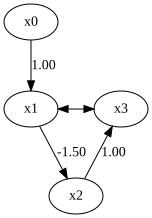

In [4]:
# Merge the coefficient matrix and the error covariance matrix to create the true graph.
omega = omega_true.copy()
np.fill_diagonal(omega, 0.0)
graph_true = B_true.T.copy()
graph_true[np.abs(omega) > 0] = np.nan

make_dot(graph_true)

## Causal Discovery

To run causal discovery, we create a `ABICLiNGAM` object and call the `fit` method. Here, we set the parameter `beta` estimated using the MGGD estimator.

In [5]:
est = MGGDEstimator()
mggd_est = est.fit(X.values)
beta_hat = float(mggd_est.beta)
print(f"beta_hat: {beta_hat}")

model = lingam.ABICLiNGAM(beta=beta_hat)
model.fit(X)

beta_hat: 2.60665829347945


Using the `coefficient_matrix_` and `error_covariance_matrix_` properties, we can see the estimated coefficient matrix and the error covariance matrix.

In [6]:
print("Estimated directed B:\n", model.coefficient_matrix_, "\n")
print("Estimated bidirected Omega:\n", model.error_covariance_matrix_)

Estimated directed B:
 [[ 0.       1.00843  0.       0.     ]
 [ 0.       0.      -1.52675 -0.93358]
 [ 0.       0.       0.       0.     ]
 [ 0.       0.       0.       0.     ]] 

Estimated bidirected Omega:
 [[ 0.27942  0.       0.      -0.16711]
 [ 0.       0.22919  0.       0.     ]
 [ 0.       0.       0.22453  0.21966]
 [-0.16711  0.       0.21966  0.46968]]


Additionally, as with other algorithms, using the `causal_order_` and `adjacency_matrix_` properties allows you to see the causal order and adjacency matrix  (with nan values for unobserved common causes).

In [7]:
print("Causal ordering =", model.causal_order_, "\n")
print("Estimated adjacency_matrix:\n", model.adjacency_matrix_)

Causal ordering = [0, 1, 3, 2] 

Estimated adjacency_matrix:
 [[ 0.       0.       0.           nan]
 [ 1.00843  0.       0.       0.     ]
 [ 0.      -1.52675  0.           nan]
 [     nan -0.93358      nan  0.     ]]


Next, we compare the estimation results using DirectLiNGAM with the same data.

In [8]:
# DirectLiNGAM
dl = lingam.DirectLiNGAM()
dl.fit(X)

true_svg = make_dot(graph_true).pipe(format='svg').decode('utf-8')
svg1 = make_dot(model.adjacency_matrix_).pipe(format='svg').decode('utf-8')
svg2 = make_dot(dl.adjacency_matrix_).pipe(format='svg').decode('utf-8')

# Display side by side using HTML
html = f"""
<div style="display: flex; gap: 40px; align-items: flex-start;">
  <div>
    <h3 style="text-align: center;">Ground Truth</h3>
    {true_svg}
  </div>
  <div>
    <h3 style="text-align: center;">ABIC-LiNGAM</h3>
    {svg1}
  </div>
  <div>
    <h3 style="text-align: center;">DirectLiNGAM</h3>
    {svg2}
  </div>
</div>
"""

display(HTML(html))

## Multiscale Bootstrap

The ordinary bootstrap estimates the bootstrap probability (BP) of a hypothesis, such as the existence of an edge, with resamples of the original size `n`. The multiscale bootstrap repeats it with several resample sizes `n'` and observes how BP changes with the scale `sa = n / n'`. From this change, the R package `scaleboot` computes the AU (approximately unbiased) p-value, which corrects the bias of BP, and the SI (selective inference) p-value, which takes into account that the hypothesis is selected from the data.

We use the `pyscaleboot` package in the `examples` directory in four steps: `MultiScaleBootstrap` runs the bootstrap on several scales, `EdgeHypothesis` and `GraphHypothesis` extract hypotheses and their BP, `RScalebootClient` converts BP to AU / SI p-values, and then we read the results. `Rscript` and the R package `scaleboot` are required.

### Settings

The package's public API has already been imported and checked in the setup cell above. The following settings configure the multiscale bootstrap.

`SCALE_RATIOS` are the ratios `n' / n` of the resample sizes, and `N_BOOTSTRAP` is the number of resamples for each scale. `MIN_CAUSAL_EFFECT` is the minimum absolute coefficient regarded as a directed edge, and `SCALEBOOT_MODELS` are the candidate models of `scaleboot`.

The bootstrap is run once. AU / SI p-values are then calculated from the resulting BP table using the `scaleboot` options in `SCALEBOOT_CONDITIONS`.

In [9]:
SCALE_RATIOS = (0.5, 0.7, 1.0, 1.4, 2.0)  # n' / n
N_BOOTSTRAP = 1000  # number of resamples for each scale
MIN_CAUSAL_EFFECT = 0.01
SCALEBOOT_MODELS = ("poly.1", "poly.2", "poly.3", "sing.3", "sphe.3")  # default of scaleboot
# options for scaleboot; the bootstrap itself is run only once
SCALEBOOT_CONDITIONS = {
    "ave": dict(models=SCALEBOOT_MODELS, select="average"),
    "best": dict(models=SCALEBOOT_MODELS, select="best"),
    "poly1": dict(models=("poly.1",), select="average"),
}
RANDOM_STATE = 0

### Saved bootstrap result

The bootstrap is time-consuming, so its result (`MultiScaleBootstrapResult`) is saved in a pickle file and loaded when you rerun this notebook.

The file name is generated from the algorithm, `N_BOOTSTRAP`, and `SCALE_RATIOS`. The random seed and data are not checked when loading; if either changes, delete the file or set `FORCE_RERUN = True`.

In [10]:
import os
import pickle

ALGORITHM = "ABICLiNGAM"
RESULT_DIR = "."  # directory of the saved bootstrap results


def result_file_path():
    ratio_text = "-".join(f"{ratio:g}" for ratio in SCALE_RATIOS)
    name = f"MultiscaleBootstrap-{ALGORITHM}_boot{N_BOOTSTRAP}_ratio{ratio_text}_msb_result.pkl"
    return os.path.join(RESULT_DIR, name)


def save_msb_result(path, msb_result):
    with open(path, "wb") as f:
        pickle.dump(msb_result, f)


def load_msb_result(path):
    with open(path, "rb") as f:
        return pickle.load(f)

### Run multiscale bootstrap (or load the saved result)

If the result file exists and `FORCE_RERUN` is False, it is loaded without running the bootstrap. Otherwise, the bootstrap runs with `MultiScaleBootstrap` and saves or overwrites the same file. Set `FORCE_RERUN = True` to run the bootstrap again and overwrite the saved file.

`MultiScaleBootstrap` takes an unfitted model that has `fit(X)` and `adjacency_matrix_`, so any LiNGAM model can be used. In this example, ABIC-LiNGAM uses the `beta` value estimated by MGGD.

In [11]:
variable_names = X.columns.tolist()

FORCE_RERUN = False  # True: run the bootstrap again and overwrite the saved file

path = result_file_path()
if os.path.exists(path) and not FORCE_RERUN:
    msb_result = load_msb_result(path)
    print(f"Loaded the saved result: {path}")
else:
    msb = MultiScaleBootstrap(
        lingam.ABICLiNGAM(beta=beta_hat),
        scale_ratios=SCALE_RATIOS,
        n_bootstrap=N_BOOTSTRAP,
        random_state=RANDOM_STATE,
    )
    msb_result = msb.bootstrap(X, variable_names=variable_names)
    save_msb_result(path, msb_result)
    print(f"Ran the bootstrap and saved the result: {path}")

Loaded the saved result: .\MultiscaleBootstrap-ABICLiNGAM_boot1000_ratio0.5-0.7-1-1.4-2_msb_result.pkl


`scale_summary()` shows the resample size `n_prime`, the scale `sa = n / n_prime`, and the numbers of successful and failed fits of each scale. A failed fit does not stop the bootstrap and is recorded in `msb_result.scales[i].failures`; BP is calculated from the successful fits only.

In [12]:
msb_result.scale_summary()

,scale_index,scale_ratio,n,n_prime,sa,n_bootstrap,n_success,n_failure
0,0,0.5,1000,500,2.000000,1000,1000,0
1,1,0.7,1000,700,1.428571,1000,1000,0
2,2,1.0,1000,1000,1.000000,1000,1000,0
3,3,1.4,1000,1400,0.714286,1000,1000,0
4,4,2.0,1000,2000,0.500000,1000,1000,0


### Extract hypotheses

`EdgeHypothesis` extracts the directed edges (`edge:from->to`) and the bidirected arcs (`arc:lower<->higher`; `NaN` in the adjacency matrix), and `GraphHypothesis` extracts the whole graphs (`graph:<hash>`). Variables in `hypothesis_id` are the column indices. Both return BP in the long format `bp_long` with one row per hypothesis and scale. `MIN_CAUSAL_EFFECT` is applied here, so it can be changed without rerunning the bootstrap.

In [13]:
edge_bp_long = EdgeHypothesis().extract(
    msb_result,
    min_causal_effect=MIN_CAUSAL_EFFECT,
)
graph_bp_long, graph_states = GraphHypothesis().extract(
    msb_result,
    min_causal_effect=MIN_CAUSAL_EFFECT,
)
bp_long = pd.concat([edge_bp_long, graph_bp_long], ignore_index=True)
print(f"{len(bp_long)} rows, {bp_long['hypothesis_id'].nunique()} hypotheses")
bp_long.head()

925 rows, 185 hypotheses


,hypothesis_id,scale_index,sa,nb,bp
0,edge:1->0,0,2.0,1000,0.082
1,edge:2->0,0,2.0,1000,0.012
2,edge:3->0,0,2.0,1000,0.012
3,edge:0->1,0,2.0,1000,0.711
4,edge:2->1,0,2.0,1000,0.005


The BP of each edge at each scale is shown below. The column `sa = 1` is the ordinary bootstrap probability, and the AU p-value takes into account how BP changes with `sa`.

In [14]:
edge_bp_long.pivot(index="hypothesis_id", columns="sa", values="bp")

sa,0.500000,0.714286,1.000000,1.428571,2.000000
hypothesis_id,,,,,
arc:0<->1,0.264,0.274,0.252,0.234,0.205
arc:0<->2,0.111,0.082,0.088,0.089,0.098
arc:0<->3,0.408,0.337,0.368,0.407,0.418
arc:1<->2,0.146,0.117,0.115,0.113,0.128
arc:1<->3,0.520,0.585,0.559,0.543,0.499
arc:2<->3,0.331,0.291,0.303,0.306,0.315
edge:0->1,0.626,0.622,0.643,0.688,0.711
edge:0->2,0.115,0.122,0.158,0.143,0.203
edge:0->3,0.217,0.235,0.243,0.220,0.217


### Calculate AU / SI p-values

`build_scaleboot_input` pivots `bp_long` into the two tables required by `scaleboot::sbfit`: `bp` (hypotheses × scales) and `scales` (the number of successful resamples `nb` and the scale `sa` of each column of `bp`). All hypotheses in `bp_long` are passed, so filter `bp_long` beforehand to restrict the hypotheses.

In [15]:
bp, scales = build_scaleboot_input(bp_long)
print(f"Number of hypotheses: {len(bp)}")
scales

Number of hypotheses: 185


,nb,sa
scale_index,,
0,1000,2.000000
1,1000,1.428571
2,1000,1.000000
3,1000,0.714286
4,1000,0.500000


`RScalebootClient().fit` runs the bundled `scaleboot.r` with `Rscript` and returns one row per hypothesis: the AU p-value (`au_pvalue`, `au_se`), the SI p-value (`si_pvalue`, `si_se`), the selected model, and its coefficients `beta0` and `beta1`. `models` are the candidate models of `sbfit`, `k` and `sk` (default 3) are the orders of the AU and SI p-values, and `select` (`"average"` or `"best"`) specifies how the models are combined.

The same `bp` and `scales` are passed to `fit` using the options in `SCALEBOOT_CONDITIONS`. The results are stored in `scaleboot_frames`.

In [16]:
scaleboot_frames = {}
for condition, options in SCALEBOOT_CONDITIONS.items():
    scaleboot_frames[condition] = RScalebootClient().fit(
        bp, scales, models=options["models"], select=options["select"]
    )
    print(f"{condition}: {len(scaleboot_frames[condition])} hypotheses")

scaleboot_frames["best"].head()

ave: 185 hypotheses
best: 185 hypotheses
poly1: 185 hypotheses


,hypothesis_id,au_pvalue,au_se,si_pvalue,si_se,best_model,beta0,beta1
0,arc:0<->1,0.611906,0.029871,0.000000,0.00000,poly.2,0.192337,0.476628
1,arc:0<->2,0.897768,0.083003,0.000000,0.00000,poly.3,0.589472,0.759643
2,arc:0<->3,0.798252,0.099358,0.044207,0.12914,poly.3,0.185897,0.146855
3,arc:1<->2,0.912103,0.069453,0.000000,0.00000,poly.3,0.486687,0.707260
4,arc:1<->3,0.153970,0.082845,0.000000,0.00000,poly.3,-0.087776,-0.077907


### Summarize the results

`final_results` holds a summary table for each scaleboot configuration. Each table has one row per hypothesis. `bp_at_sa1` is BP at the scale closest to `sa = 1` (the ordinary bootstrap probability), and the other columns include the AU / SI p-values from `scaleboot`. `relation` shows the variable names of the edges and arcs.

In [17]:
def relation_label(hypothesis_id):
    """Convert 'edge:0->1' to 'x0->x1' (None for the graph hypotheses)."""
    kind, relation = hypothesis_id.split(":")
    if kind == "graph":
        return None
    sep = "<->" if kind == "arc" else "->"
    source, destination = (variable_names[int(v)] for v in relation.split(sep))
    return f"{source}{sep}{destination}"


bp_at_sa1 = (
    bp_long.assign(_sa_distance=lambda frame: (frame["sa"] - 1.0).abs())
    .sort_values(["hypothesis_id", "_sa_distance", "scale_index"])
    .drop_duplicates("hypothesis_id")
    .loc[:, ["hypothesis_id", "bp"]]
    .rename(columns={"bp": "bp_at_sa1"})
)


def summarize(scaleboot_frame):
    result = (
        bp_at_sa1.merge(scaleboot_frame, on="hypothesis_id", how="inner", validate="one_to_one")
        .assign(hypothesis_type=lambda frame: frame["hypothesis_id"].str.split(":").str[0])
        .sort_values(["hypothesis_type", "au_pvalue", "hypothesis_id"], ascending=[True, False, True])
        .reset_index(drop=True)
    )
    result["relation"] = result["hypothesis_id"].map(relation_label)
    return result


final_results = {condition: summarize(frame) for condition, frame in scaleboot_frames.items()}
conditions = list(final_results)

# best_model is the candidate with the smallest AIC, independent of `select`
final_results["best"].loc[
    final_results["best"]["hypothesis_type"] != "graph",
    ["relation", "bp_at_sa1", "au_pvalue", "au_se", "si_pvalue", "si_se", "best_model"],
]

,relation,bp_at_sa1,au_pvalue,au_se,si_pvalue,si_se,best_model
0,x1<->x2,0.115,0.912103,0.069453,0.000000,0.000000,poly.3
1,x0<->x2,0.088,0.897768,0.083003,0.000000,0.000000,poly.3
2,x0<->x3,0.368,0.798252,0.099358,0.044207,0.129140,poly.3
3,x2<->x3,0.303,0.762437,0.112174,0.000000,0.000000,poly.3
4,x0<->x1,0.252,0.611906,0.029871,0.000000,0.000000,poly.2
5,x1<->x3,0.559,0.153970,0.082845,0.000000,0.000000,poly.3
6,x3->x1,0.038,0.938043,0.072144,0.000000,0.000000,poly.3
7,x1->x3,0.377,0.712250,0.120517,0.000000,0.000000,poly.3
8,x2->x1,0.003,0.664346,0.098519,0.000000,0.000000,poly.2
9,x0->x2,0.158,0.654435,0.155835,0.000000,0.000000,poly.3


The AU / SI p-values for edge and arc hypotheses are shown side by side. The standard errors (`au_se`, `si_se`) are available in `final_results[condition]`.

In [18]:
EDGE_COLUMNS = ["au_pvalue", "si_pvalue", "best_model"]

comparison = final_results["best"].loc[
    final_results["best"]["hypothesis_type"] != "graph", ["hypothesis_id", "relation", "bp_at_sa1"]
]
for condition, result in final_results.items():
    part = result[["hypothesis_id"] + EDGE_COLUMNS].rename(
        columns={c: f"{c}_{condition}" for c in EDGE_COLUMNS}
    )
    comparison = comparison.merge(part, on="hypothesis_id", validate="one_to_one")

comparison = (
    comparison.sort_values(["au_pvalue_best", "hypothesis_id"], ascending=[False, True])
    .reset_index(drop=True)
)
comparison[
    ["relation", "bp_at_sa1"] + [f"{c}_{condition}" for condition in conditions for c in EDGE_COLUMNS]
]

,relation,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,best_model_ave,au_pvalue_best,si_pvalue_best,best_model_best,au_pvalue_poly1,si_pvalue_poly1,best_model_poly1
0,x3->x1,0.038,0.870008,0.000000,poly.3,0.938043,0.000000,poly.3,0.042020,0.000000,poly.1
1,x1<->x2,0.115,0.878536,0.000000,poly.3,0.912103,0.000000,poly.3,0.141932,0.000000,poly.1
2,x0<->x2,0.088,0.843430,0.000000,poly.3,0.897768,0.000000,poly.3,0.108273,0.000000,poly.1
3,x0<->x3,0.368,0.761103,0.039588,poly.3,0.798252,0.044207,poly.3,0.394158,0.000000,poly.1
4,x2<->x3,0.303,0.665399,0.000000,poly.3,0.762437,0.000000,poly.3,0.324151,0.000000,poly.1
5,x1->x3,0.377,0.591124,0.000000,poly.3,0.712250,0.000000,poly.3,0.391660,0.000000,poly.1
6,x2->x1,0.003,0.733141,0.000000,poly.2,0.664346,0.000000,poly.2,0.005001,0.000000,poly.1
7,x0->x2,0.158,0.552064,0.000000,poly.3,0.654435,0.000000,poly.3,0.156628,0.000000,poly.1
8,x3->x0,0.011,0.723904,0.000000,poly.2,0.620419,0.000000,poly.2,0.012913,0.000000,poly.1
9,x0<->x1,0.252,0.575209,0.000000,poly.2,0.611906,0.000000,poly.2,0.268079,0.000000,poly.1


Directed edges and bidirected arcs with nonzero AU values are drawn from the results. Edge and arc labels show AU p-values to four decimal places. Edges or arcs with AU p-values of 0 or NaN are omitted.

Condition: ave


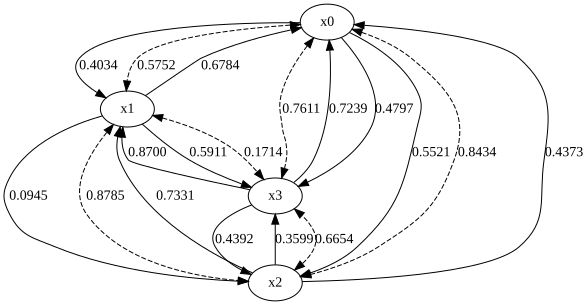

Condition: best


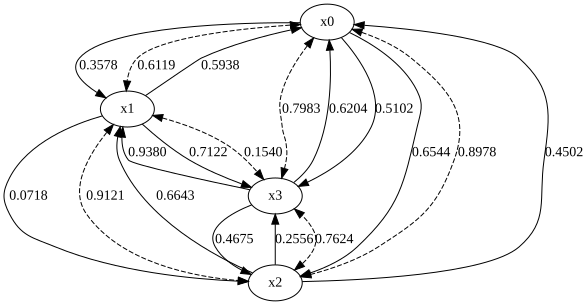

Condition: poly1


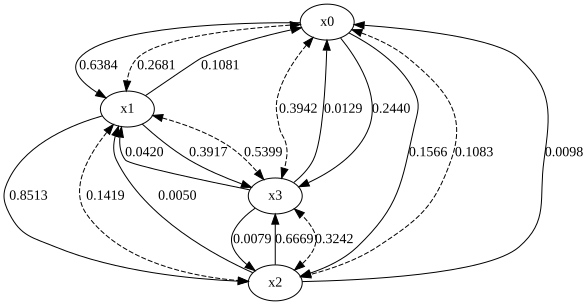

In [19]:
AU_LABEL_FORMAT = "{:.4f}"  # make_dot rounds to 2 digits, so 0.995 or more is shown as 1.00

for condition, result in final_results.items():
    g = graphviz.Digraph(engine="dot")
    for name in variable_names:
        g.node(name)
    for _, row in result[result["hypothesis_type"] == "edge"].iterrows():
        au_pvalue = row["au_pvalue"]
        if np.isnan(au_pvalue) or au_pvalue == 0:
            continue
        source, destination = map(int, row["hypothesis_id"].split(":")[1].split("->"))
        g.edge(variable_names[source], variable_names[destination], label=AU_LABEL_FORMAT.format(au_pvalue))
    for _, row in result[result["hypothesis_type"] == "arc"].iterrows():
        au_pvalue = row["au_pvalue"]
        if np.isnan(au_pvalue) or au_pvalue == 0:
            continue
        lower, higher = map(int, row["hypothesis_id"].split(":")[1].split("<->"))
        g.edge(
            variable_names[lower],
            variable_names[higher],
            dir="both",
            style="dashed",
            label=AU_LABEL_FORMAT.format(au_pvalue),
        )
    print(f"Condition: {condition}")
    display(g)

### Whole-graph hypothesis

`graph_states` holds the edge-state matrix (0: no edge, 1: directed edge, 2: bidirected edge) of every graph hypothesis. `graph_comparison` combines BP at the scale closest to `sa = 1` with the AU / SI p-values for each graph hypothesis.

In [20]:
GRAPH_COLUMNS = ["au_pvalue", "si_pvalue"]

graph_comparison = final_results["best"].loc[
    final_results["best"]["hypothesis_type"] == "graph", ["hypothesis_id", "bp_at_sa1"]
]
for condition, result in final_results.items():
    part = result[["hypothesis_id"] + GRAPH_COLUMNS].rename(
        columns={c: f"{c}_{condition}" for c in GRAPH_COLUMNS}
    )
    graph_comparison = graph_comparison.merge(part, on="hypothesis_id", validate="one_to_one")

graph_comparison = graph_comparison.sort_values(
    ["au_pvalue_best", "bp_at_sa1", "hypothesis_id"], ascending=[False, False, True]
).reset_index(drop=True)
print(f"{len(graph_comparison)} graph hypotheses")
graph_comparison

167 graph hypotheses


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:80000c1da4e2b3eff1b2a401d2e14bde66ec8933,0.000,0.590007,0.464585,1.000000,0.895562,0.000310,0.0
1,graph:7d8be1a287ecbd8792482f265530fa73c8fcf99f,0.001,0.783007,0.000000,0.992965,0.000000,0.001185,0.0
2,graph:da60403ee353a8024404c6d4eefb64ceab93f579,0.056,0.774221,0.000000,0.854751,0.000000,0.082937,0.0
3,graph:89219d1629627afe54845301367195d6813d3181,0.008,0.772325,0.000000,0.646186,0.000000,0.006158,0.0
4,graph:c517339ca689c461ce65b7628a800ac2b7d7a564,0.004,0.501455,0.000000,0.634524,0.000000,0.003644,0.0
...,...,...,...,...,...,...,...,...
162,graph:743e158c57bc5cdf246e182dd9884eb4deacdac1,0.000,0.000328,0.000000,0.000008,0.000000,0.000008,0.0
163,graph:ac795b593d8cd1617f17e50b0c1160193b04139f,0.000,0.000328,0.000000,0.000008,0.000000,0.000008,0.0
164,graph:cbb01f1fd9a61619fbf84092ab08da865949c6aa,0.000,0.000328,0.000000,0.000008,0.000000,0.000008,0.0
165,graph:f039ee0d3ce5644cbbf10ea9d6a0e8b893c5ab2d,0.000,0.000328,0.000000,0.000008,0.000000,0.000008,0.0


`graph_comparison` is sorted by AU p-value. For each result, the top `TOP_GRAPH_COUNT` graphs are drawn in descending order of AU p-value. A graph with a high AU p-value does not necessarily have a high BP.

Condition: ave


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
1,graph:7d8be1a287ecbd8792482f265530fa73c8fcf99f,0.001,0.783007,0.0,0.992965,0.0,0.001185,0.0
2,graph:da60403ee353a8024404c6d4eefb64ceab93f579,0.056,0.774221,0.0,0.854751,0.0,0.082937,0.0
3,graph:89219d1629627afe54845301367195d6813d3181,0.008,0.772325,0.0,0.646186,0.0,0.006158,0.0
6,graph:0b73588ebcea003abadbdd9a7e1056130d9f8be9,0.001,0.719239,0.0,0.584248,0.0,0.009773,0.0
10,graph:d5d5819593994680328bfadc597c1af12fb28da7,0.005,0.658842,0.0,0.534700,0.0,0.007718,0.0


Rank 1: BP=0.001; ave: AU=0.783 SI=0.000, best: AU=0.993 SI=0.000, poly1: AU=0.001 SI=0.000


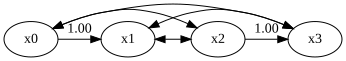

Rank 2: BP=0.056; ave: AU=0.774 SI=0.000, best: AU=0.855 SI=0.000, poly1: AU=0.083 SI=0.000


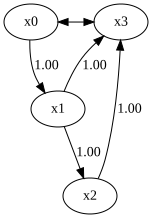

Rank 3: BP=0.008; ave: AU=0.772 SI=0.000, best: AU=0.646 SI=0.000, poly1: AU=0.006 SI=0.000


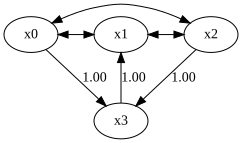

Rank 4: BP=0.001; ave: AU=0.719 SI=0.000, best: AU=0.584 SI=0.000, poly1: AU=0.010 SI=0.000


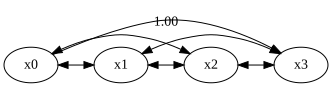

Rank 5: BP=0.005; ave: AU=0.659 SI=0.000, best: AU=0.535 SI=0.000, poly1: AU=0.008 SI=0.000


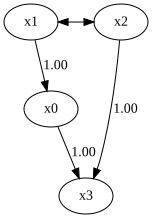

Condition: best


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
0,graph:80000c1da4e2b3eff1b2a401d2e14bde66ec8933,0.000,0.590007,0.464585,1.000000,0.895562,0.000310,0.0
1,graph:7d8be1a287ecbd8792482f265530fa73c8fcf99f,0.001,0.783007,0.000000,0.992965,0.000000,0.001185,0.0
2,graph:da60403ee353a8024404c6d4eefb64ceab93f579,0.056,0.774221,0.000000,0.854751,0.000000,0.082937,0.0
3,graph:89219d1629627afe54845301367195d6813d3181,0.008,0.772325,0.000000,0.646186,0.000000,0.006158,0.0
4,graph:c517339ca689c461ce65b7628a800ac2b7d7a564,0.004,0.501455,0.000000,0.634524,0.000000,0.003644,0.0


Rank 1: BP=0.000; ave: AU=0.590 SI=0.465, best: AU=1.000 SI=0.896, poly1: AU=0.000 SI=0.000


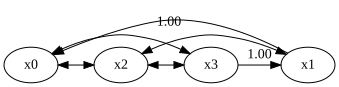

Rank 2: BP=0.001; ave: AU=0.783 SI=0.000, best: AU=0.993 SI=0.000, poly1: AU=0.001 SI=0.000


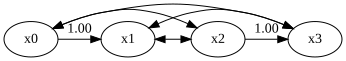

Rank 3: BP=0.056; ave: AU=0.774 SI=0.000, best: AU=0.855 SI=0.000, poly1: AU=0.083 SI=0.000


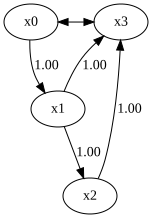

Rank 4: BP=0.008; ave: AU=0.772 SI=0.000, best: AU=0.646 SI=0.000, poly1: AU=0.006 SI=0.000


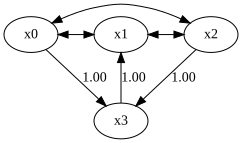

Rank 5: BP=0.004; ave: AU=0.501 SI=0.000, best: AU=0.635 SI=0.000, poly1: AU=0.004 SI=0.000


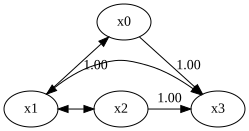

Condition: poly1


,hypothesis_id,bp_at_sa1,au_pvalue_ave,si_pvalue_ave,au_pvalue_best,si_pvalue_best,au_pvalue_poly1,si_pvalue_poly1
7,graph:96c37c7af4c05173e13dd48451af4d6c8526c447,0.240,0.528785,0.0,0.559039,0.0,0.257403,0.0
12,graph:8ccc796f25d7915ea1695144ff9b58830b35e01c,0.193,0.619296,0.0,0.526490,0.0,0.220166,0.0
2,graph:da60403ee353a8024404c6d4eefb64ceab93f579,0.056,0.774221,0.0,0.854751,0.0,0.082937,0.0
5,graph:3bf89b132199313ba6d987d28f3235236854f19e,0.062,0.558992,0.0,0.584871,0.0,0.081556,0.0
17,graph:feefe2107d0b36f410c8b474582d4d3a112ec27c,0.046,0.395899,0.0,0.501883,0.0,0.047754,0.0


Rank 1: BP=0.240; ave: AU=0.529 SI=0.000, best: AU=0.559 SI=0.000, poly1: AU=0.257 SI=0.000


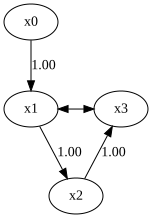

Rank 2: BP=0.193; ave: AU=0.619 SI=0.000, best: AU=0.526 SI=0.000, poly1: AU=0.220 SI=0.000


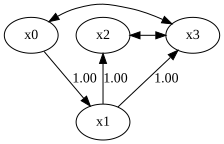

Rank 3: BP=0.056; ave: AU=0.774 SI=0.000, best: AU=0.855 SI=0.000, poly1: AU=0.083 SI=0.000


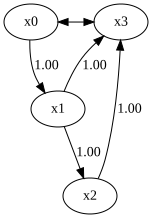

Rank 4: BP=0.062; ave: AU=0.559 SI=0.000, best: AU=0.585 SI=0.000, poly1: AU=0.082 SI=0.000


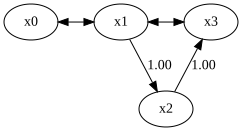

Rank 5: BP=0.046; ave: AU=0.396 SI=0.000, best: AU=0.502 SI=0.000, poly1: AU=0.048 SI=0.000


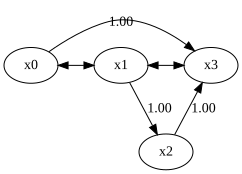

In [21]:
def draw_graph(graph_id):
    state = graph_states[graph_id]
    adjacency = state.astype(float)
    adjacency[state == 2] = np.nan  # bidirected edge
    return make_dot(adjacency, labels=variable_names)


TOP_GRAPH_COUNT = 5

for condition in conditions:
    top_graph_rows = graph_comparison.sort_values(
        [f"au_pvalue_{condition}", "bp_at_sa1", "hypothesis_id"], ascending=[False, False, True]
    ).head(TOP_GRAPH_COUNT)
    print(f"Condition: {condition}")
    display(top_graph_rows)

    for rank, (_, row) in enumerate(top_graph_rows.iterrows(), start=1):
        pvalues = ", ".join(
            f"{c}: AU={row[f'au_pvalue_{c}']:.3f} SI={row[f'si_pvalue_{c}']:.3f}"
            for c in conditions
        )
        print(f"Rank {rank}: BP={row['bp_at_sa1']:.3f}; {pvalues}")
        display(draw_graph(row["hypothesis_id"]))